In [1]:
## Import Libraries

In [2]:
import pandas as pd
import numpy as np
import os

In [3]:
## import Dataset

In [4]:
Df=pd.read_csv('House_Rent_Dataset.csv')

In [5]:
Df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [7]:
Df.shape

(4746, 12)

In [8]:
Df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


In [9]:
Df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.746000e+03,4746.000000,4746.000000
mean,2.083860,3.499345e+04,967.490729,1.965866
std,0.832256,7.810641e+04,634.202328,0.884532
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


In [10]:
Df.isnull().sum()

Posted On            0
BHK                  0
Rent                 0
Size                 0
Floor                0
Area Type            0
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             0
Point of Contact     0
dtype: int64

In [11]:
Df['City'].value_counts()

City
Mumbai       972
Chennai      891
Bangalore    886
Hyderabad    868
Delhi        605
Kolkata      524
Name: count, dtype: int64

In [12]:
## Splitting Target and Features

In [15]:
x=Df.drop(columns=['Rent','Posted On','Point of Contact','Floor','Area Locality'])
y=Df['Rent']

In [16]:
x.head()

,BHK,Size,Area Type,City,Furnishing Status,Tenant Preferred,Bathroom
0,2,1100,Super Area,Kolkata,Unfurnished,Bachelors/Family,2
1,2,800,Super Area,Kolkata,Semi-Furnished,Bachelors/Family,1
2,2,1000,Super Area,Kolkata,Semi-Furnished,Bachelors/Family,1
3,2,800,Super Area,Kolkata,Unfurnished,Bachelors/Family,1
4,2,850,Carpet Area,Kolkata,Unfurnished,Bachelors,1


In [17]:
y.head()

0    10000
1    20000
2    17000
3    10000
4     7500
Name: Rent, dtype: int64

In [18]:
## Splitting train_test_split

In [20]:
from sklearn.model_selection import train_test_split

In [21]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [22]:
cat_cols=['Area Type','City','Furnishing Status','Tenant Preferred']

In [23]:
## Encoding

In [24]:
from sklearn.preprocessing import OneHotEncoder

In [31]:
encoder=OneHotEncoder(handle_unknown='ignore', sparse_output=False)
x_train_encoded=encoder.fit_transform(x_train[cat_cols])
x_test_encoded=encoder.transform(x_test[cat_cols])

In [32]:
num_cols=['BHK','Size','Bathroom']

In [34]:
new_cols=encoder.get_feature_names_out(cat_cols)
x_train_encoded=pd.DataFrame(x_train_encoded,columns=new_cols,index=x_train.index)
x_test_encoded=pd.DataFrame(x_test_encoded, columns=new_cols,index=x_test.index)

In [37]:
x_train_final=pd.concat([x_train[num_cols],x_train_encoded],axis=1)
x_test_final=pd.concat([x_test[num_cols],x_test_encoded],axis=1)

In [38]:
## Model Linear regression

In [46]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error,mean_absolute_error

In [51]:
model=LinearRegression()
model.fit(x_train_final,y_train)
y_pred=model.predict(x_test_final)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f'R2 Score:{r2_score(y_test,y_pred):.2f}')
print(f'RMSE:{rmse:.2f}')
print(f'MAE:{mean_absolute_error(y_test,y_pred):.2f}')

R2 Score:0.52
RMSE:43764.14
MAE:22439.91


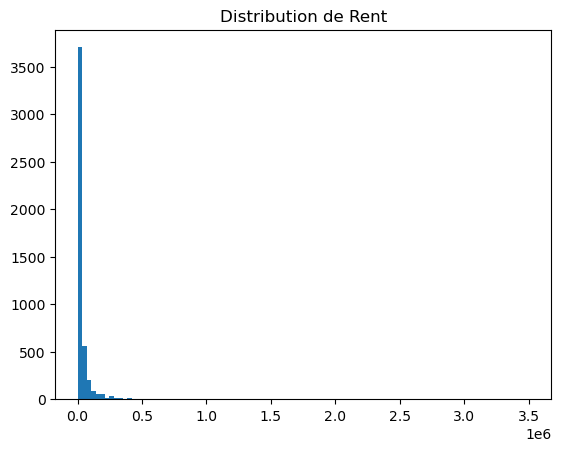

In [52]:
import matplotlib.pyplot as plt

plt.hist(Df['Rent'], bins=100)
plt.title("Distribution de Rent")
plt.show()

In [53]:
Df['Rent'].describe()

count    4.746000e+03
mean     3.499345e+04
std      7.810641e+04
min      1.200000e+03
25%      1.000000e+04
50%      1.600000e+04
75%      3.300000e+04
max      3.500000e+06
Name: Rent, dtype: float64

In [54]:
print(Df['Rent'].quantile(0.99))

300000.0


In [55]:
# 1. we Clean
Df_clean = Df[Df['Rent'] < 300000].copy()
print(f"Before: {len(Df)} lignes, After: {len(Df_clean)} lignes")

Before: 4746 lignes, After: 4693 lignes


In [56]:
# 2. We Split X et y avec le clean
x_clean = Df_clean.drop(['Rent', 'Posted On', 'Floor', 'Area Locality', 'Point of Contact'], axis=1)
y_clean = Df_clean['Rent']

In [57]:
from sklearn.compose import ColumnTransformer
import numpy as np

In [58]:
x_train, x_test, y_train, y_test = train_test_split(x_clean, y_clean, test_size=0.2, random_state=42)

In [59]:
num_cols = x_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = x_train.select_dtypes(include='object').columns.tolist()

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
], remainder='passthrough')

x_train_final = preprocessor.fit_transform(x_train)
x_test_final = preprocessor.transform(x_test)

In [60]:
model = LinearRegression()
model.fit(x_train_final, y_train)
y_pred = model.predict(x_test_final)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f'R2 Score: {r2_score(y_test,y_pred):.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'MAE: {mean_absolute_error(y_test,y_pred):.2f}')

R2 Score: 0.63
RMSE: 23783.09
MAE: 15043.26


In [61]:
from sklearn.ensemble import RandomForestRegressor

In [62]:
model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(x_train_final, y_train)
y_pred = model.predict(x_test_final)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f'R2 Score: {r2_score(y_test,y_pred):.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'MAE: {mean_absolute_error(y_test,y_pred):.2f}')

R2 Score: 0.74
RMSE: 20013.44
MAE: 9775.22


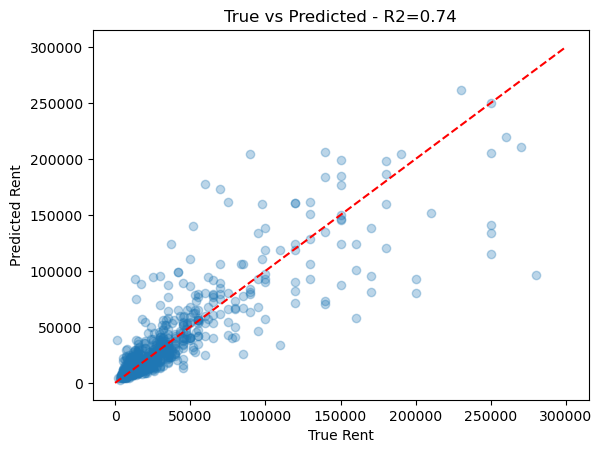

In [63]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel("True Rent")
plt.ylabel("Predicted Rent")
plt.title("True vs Predicted - R2=0.74")
plt.plot([0, 300000], [0, 300000], 'r--') # perfect line
plt.show()

In [64]:
print(f"Final Model: RandomForest")
print(f"R2: 0.74 -> we explain 74% of the rent")
print(f"Average Error: 9,775 Rs")

Final Model: RandomForest
R2: 0.74 -> we explain 74% of the rent
Average Error: 9,775 Rs
